# 密立根油滴实验 (Millikan Oil Drop Experiment)

本 Notebook 用于对近代物理经典实验——**《密立根油滴实验》（中国海洋大学物理实验实测数据）**进行全流程自动化处理、电荷量子化检验、统计不确定度评定与可视化分析。包含平衡法与动态法数据计算模型、油滴半径与非连续介质粘滞力修正、倒算电荷数与最小二乘法拟合测定基本元电荷 $e$、以及严格遵循 JJF 1059 国家计量规范的“四舍六入五凑偶”有效数字修约。

---
### 一、 实验背景与目的

油滴实验是近代物理学中测量基本电荷 $e$（元电荷）的经典范式。1909~1913 年，美国物理学家罗伯特·密立根（Robert A. Millikan）巧妙地将微观带电量测量转化为宏观微米级油滴在均匀电场和重力场中的力学平衡与运动学问题，获得了高精度的基本电荷值（荣获 1923 年诺贝尔物理学奖）。现代推荐国际公认元电荷基准值为：
$$e_0 = 1.602\,176\,634 \times 10^{-19}\ \mathrm{C}$$

**实验目的**：
1. 掌握用油滴法测量电子基本电荷 $e$ 的动力学原理与实验方法（平衡法与动态法）；
2. 验证电荷的不连续性（电荷量子化假设 $q = n \cdot e$）；
3. 学习通过显微 CCD 摄像监视系统跟踪微米级粒子并记录时间和平衡电压；
4. 掌握间接测量微弱物理量的不确定度传递与最小二乘法回归拟合分析。

---
### 二、 实验原理与数学物理公式体系

#### 1. 动力学平衡与斯托克斯阻力定律
设微小钟表油滴半径为 $r$，质量为 $m_1$，在空气中受重力 $m_1 g$ 与浮力 $m_2 g$ 作用，视重为：
$$m_1 g - m_2 g = \frac{4}{3} \pi r^3 (\rho_1 - \rho_2) g \tag{1}$$
* $\rho_1$：钟表油密度（$20^\circ\mathrm{C}$ 时约 $981\ \mathrm{kg/m^3}$）
* $\rho_2$：空气密度（常温常压下约 $1.2928\ \mathrm{kg/m^3}$）
* $g$：重力加速度（青岛本地值取 $9.794\ \mathrm{m/s^2}$）

油滴在粘滞流体（空气）中运动时受到与速度成正比的斯托克斯阻力 $F_f = K v = 6\pi\eta r v$（$\eta$ 为空气动力粘度）。

#### 2. 空气介质非连续性与有效粘度修正 (Cunningham Correction)
当油滴半径 $r \approx 0.4 \sim 1.0\ \mu\mathrm{m}$ 时，其尺度已与空气分子的平均自由程相当，空气已不能严格视作连续介质，油滴在分子间隙中的阻力减小。因此，斯托克斯公式中的空气粘度 $\eta$ 需修正为有效粘度 $\eta'$：
$$\eta' = \frac{\eta}{1 + \frac{b}{p r}} \tag{2}$$
* $p$：大气压强（标准状况取 $101\,325\ \mathrm{Pa} = 76.0\ \mathrm{cmHg}$）
* $b$：修正常数，理论与实测取 $b = 8.23 \times 10^{-3}\ \mathrm{N/m} = 6.17 \times 10^{-6}\ \mathrm{m\cdot cmHg}$

油滴在重力场中无电场匀速下落距离 $s$ 历时 $t_f$（速度 $v_f = s / t_f$），由 $m_1 g - m_2 g = 6\pi\eta r v_f$ 解得未修正油滴半径：
$$r = \sqrt{\frac{9 \eta v_f}{2 g (\rho_1 - \rho_2)}} = \sqrt{\frac{9 \eta s}{2 g (\rho_1 - \rho_2) t_f}} \tag{3}$$

#### 3. 平衡法 (Balance Method) 计算公式
在平行极板（极距为 $d$）间施加平衡电压 $U$，形成向上的匀强电场 $E = U / d$。调节 $U$ 使带电量为 $q$ 的油滴在视场中静止受力平衡：
$$q E = q \frac{U}{d} = (m_1 - m_2)g \tag{4}$$
断开电场使极板电压降为 $0\ \mathrm{V}$，油滴在重力场中匀速下落，测得下落距离 $s$ 耗时 $t_f$。综合式 (1) ~ (4)，严格导出油滴所带电荷量 $q$ 的计算公式：
$$q = 9\sqrt{2}\pi d \left[ \frac{(\eta s)^3}{(\rho_1 - \rho_2)g} \right]^{1/2} \frac{1}{U t_f^{3/2} \left( 1 + \frac{b}{p r} \right)^{3/2}} = C_g \cdot \frac{1}{U t_f^{3/2} \left( 1 + \frac{b}{p r} \right)^{3/2}} \tag{5}$$
其中 $C_g$ 为由实验仪器几何尺寸与流体物性决定的**仪器常数**：
$$C_g = 9\sqrt{2}\pi d \left[ \frac{(\eta s)^3}{(\rho_1 - \rho_2)g} \right]^{1/2} \tag{6}$$

#### 4. 动态法 (Dynamic Method) 计算公式
若采用动态法，先断电测定油滴在重力场中匀速下落时间 $t_f$（速度 $v_f = s/t_f$）；再施加提升反向高压 $U_r$，测定油滴匀速提升距离 $s$ 的时间 $t_r$（速度 $v_r = s/t_r$），油滴带电量满足：
$$q = C_g \cdot \frac{1}{U_r} \left( \frac{1}{t_r} + \frac{1}{t_f} \right) \frac{1}{t_f^{1/2} \left( 1 + \frac{b}{p r} \right)^{3/2}} \tag{7}$$

#### 5. 环境温度自适应修正模型
* **钟表油密度 $\rho_1(T)$**（温度 $T\in[0, 40]^\circ\mathrm{C}$）：
  $$\rho_1(T) = 981 - 0.5 \times (T - 20)\ \mathrm{kg/m^3}$$
* **空气粘度苏士兰公式 (Sutherland's Formula)**：
  $$\eta(T) = \mu_0 \left(\frac{T_K}{T_0}\right)^n \frac{T_0 + T'}{T_K + T'}$$
  （$T_0 = 273.15\ \mathrm{K}, \mu_0 = 1.71 \times 10^{-5}\ \mathrm{Pa\cdot s}, n = 0.7, T' = 110\ \mathrm{K}, T_K = T(^\circ\mathrm{C}) + 273.15$）

#### 6. 元电荷求解与量子化验证法则
1. **计算法（倒算整数电子数法）**：
   对每颗测得电荷量 $q_i$ 的油滴，通过理论元电荷 $e_0$ 倒算其携带的整数电子数：
   $$n_i = \operatorname{round}\left( \frac{q_i}{e_0} \right) \quad (n_i \in \{1, 2, 3, \dots, 10\}) \tag{8}$$
   单电子电荷实验值：$e_i = \frac{q_i}{n_i}$。多颗油滴实验均值 $\bar{e} = \frac{1}{N}\sum_{i=1}^N e_i$。
2. **作图法（最小二乘法一元线性拟合）**：
   以电荷数 $n_i$ 为自变量，$q_i$ 为因变量拟合直线 $q = k \cdot n + b_0$。直线斜率 $k$ 即为拟合测定的元电荷值：$e_{\mathrm{fit}} = k$。

In [1]:
import math
from decimal import Decimal
from typing import TypedDict
import matplotlib.pyplot as plt
import numpy as np

# 导入项目中 utils 通用物理计算与规范修约工具
from python.utils import (
    scientific_round,
    calculate_stats,
    linear_regression
)

# 配置 matplotlib 图表矢量渲染与中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

print("密立根油滴实验计算与分析模块加载完成。")

密立根油滴实验计算与分析模块加载完成。


### 1. 实验仪器参数、环境条件与中国海洋大学实测原始数据配置
> **说明**：下方数据来自《中国海洋大学实验报告》原始数据记录单：
> - 5 颗油滴的平衡电压 $U$（单位：$\mathrm{V}$）分别为 $26, 47, 24, 38, 82\ \mathrm{V}$；
> - 每颗油滴均测量 3 次下落时间 $t$（单位：$\mathrm{s}$）。

In [2]:
# ==========================================
# 1. 环境条件与物理常量 (国际单位制)
# ==========================================
T_ENV = Decimal("20.0")           # 实验室内温度 (°C)
P_ATM = Decimal("101325")         # 实验室气压 (Pa)
G_ACCEL = Decimal("9.794")        # 本地重力加速度 g (m/s^2，青岛本地)
B_CORR = Decimal("0.00823")       # 空气粘度修正系数 b (N/m)
E_ACCEPTED = Decimal("1.602176634e-19") # 理论公认元电荷基准值 e0 (C)

# ==========================================
# 2. 仪器结构参数与允差 (以实验讲义附录为准)
# ==========================================
PLATE_D = Decimal("0.00500")      # 平行极板间距 d = 5.00 mm = 5.00e-3 m
FALL_S = Decimal("0.00150")       # CCD视场匀速下落距离 s = 1.50 mm = 1.50e-3 m
RHO_AIR = Decimal("1.2928")       # 空气密度 ρ2 (kg/m^3)

# 仪器仪表误差限 Δ_inst
DELTA_U = Decimal("0.5")          # 数字高压电压表误差限 ΔU (V)
DELTA_T = Decimal("0.05")         # 电子计时器误差限 Δt (s)
DELTA_D = Decimal("0.01e-3")      # 极板间距加工允差 Δd (m)
DELTA_S = Decimal("0.01e-3")      # 标尺刻度允差 Δs (m)

# 空气动力粘度 η (20°C 标称值 1.83e-5 kg/(m·s))
ETA_PRESET = Decimal("1.83e-5")

# 钟表油密度 ρ1 (20°C 标称值 981 kg/m^3)
RHO_OIL = Decimal("981.0") - Decimal("0.5") * (T_ENV - Decimal("20.0"))
RHO_EFF = RHO_OIL - RHO_AIR       # 有效净密度差 (ρ1 - ρ2)

# ==========================================
# 3. 中国海洋大学实验报告原始数据类型定义与配置
# ==========================================
class OilDropletRecord(TypedDict):
    id: int
    name: str
    U_runs: list[Decimal]
    t_runs: list[Decimal]

oil_droplets_raw: list[OilDropletRecord] = [
    {
        "id": 1,
        "name": "油滴 1#",
        "U_runs": [Decimal("26.0")],
        "t_runs": [Decimal("85.12"), Decimal("87.54"), Decimal("84.94")]
    },
    {
        "id": 2,
        "name": "油滴 2#",
        "U_runs": [Decimal("47.0")],
        "t_runs": [Decimal("62.46"), Decimal("62.20"), Decimal("65.07")]
    },
    {
        "id": 3,
        "name": "油滴 3#",
        "U_runs": [Decimal("24.0")],
        "t_runs": [Decimal("92.59"), Decimal("93.46"), Decimal("96.28")]
    },
    {
        "id": 4,
        "name": "油滴 4#",
        "U_runs": [Decimal("38.0")],
        "t_runs": [Decimal("29.45"), Decimal("30.02"), Decimal("29.27")]
    },
    {
        "id": 5,
        "name": "油滴 5#",
        "U_runs": [Decimal("82.0")],
        "t_runs": [Decimal("15.65"), Decimal("15.27"), Decimal("15.70")]
    }
]

print(f"实验配置加载完成: 环境温度 {T_ENV}°C, 大气压 {P_ATM} Pa, 钟表油有效密度 {RHO_EFF:.2f} kg/m^3")
print(f"已录入实测油滴总数: {len(oil_droplets_raw)} 组")
for drop in oil_droplets_raw:
    t_runs_list: list[Decimal] = drop["t_runs"]
    u_runs_list: list[Decimal] = drop["U_runs"]
    t_str = ", ".join(str(t) for t in t_runs_list)
    print(f"- {drop['name']}: 平衡电压 U = {u_runs_list[0]} V, 3次下落时间 t = [{t_str}] s")

实验配置加载完成: 环境温度 20.0°C, 大气压 101325 Pa, 钟表油有效密度 979.71 kg/m^3
已录入实测油滴总数: 5 组
- 油滴 1#: 平衡电压 U = 26.0 V, 3次下落时间 t = [85.12, 87.54, 84.94] s
- 油滴 2#: 平衡电压 U = 47.0 V, 3次下落时间 t = [62.46, 62.20, 65.07] s
- 油滴 3#: 平衡电压 U = 24.0 V, 3次下落时间 t = [92.59, 93.46, 96.28] s
- 油滴 4#: 平衡电压 U = 38.0 V, 3次下落时间 t = [29.45, 30.02, 29.27] s
- 油滴 5#: 平衡电压 U = 82.0 V, 3次下落时间 t = [15.65, 15.27, 15.70] s


### 2. 核心数据处理：油滴半径、连续性修正与带电量计算
依据实验原理计算：
1. **仪器常数** $C_g = 9\sqrt{2}\pi d \left[ \frac{(\eta s)^3}{(\rho_1 - \rho_2)g} \right]^{1/2}$；
2. 每颗油滴的**未修正半径** $r = \sqrt{\frac{9\eta s}{2g(\rho_1 - \rho_2)t_f}}$ 与有效粘滞力**修正因子** $\left(1 + \frac{b}{pr}\right)^{-3/2}$；
3. **带电量** $q = C_g \frac{1}{U t_f^{3/2} (1 + b/(pr))^{3/2}}$；
4. 倒算**电荷数** $n_i = \operatorname{round}(q_i / e_0)$ 与**单电子电荷** $e_i = q_i / n_i$。

In [3]:
# 1. 计算仪器几何流体常数 C_g
pi_dec = Decimal(str(math.pi))
sqrt2_dec = Decimal(str(math.sqrt(2.0)))
eta_s_cubed = (ETA_PRESET * FALL_S) ** Decimal("3")
C_g = Decimal("9") * sqrt2_dec * pi_dec * PLATE_D * Decimal(str(math.sqrt(float(eta_s_cubed / (RHO_EFF * G_ACCEL)))))

print(f"仪器综合常数 C_g: {C_g:.6e} N^(3/2)·s^(3/2)·m^(1/2) / kg^(1/2)")

# 2. 逐组处理各油滴实测数据类型定义
class DropletResult(TypedDict):
    id: int
    name: str
    u_mean: Decimal
    u_uc: Decimal
    t_mean: Decimal
    t_uc: Decimal
    r_um: Decimal
    corr_factor: Decimal
    q: Decimal
    u_q: Decimal
    n_float: float
    n: int
    e: Decimal
    u_e: Decimal

droplet_results: list[DropletResult] = []

for drop in oil_droplets_raw:
    u_list: list[Decimal] = drop["U_runs"]
    t_list: list[Decimal] = drop["t_runs"]
    
    # 统计平衡电压 U 与下落时间 t 的均值与标准不确定度
    u_mean, u_uc, u_ua, u_ub, u_s = calculate_stats(u_list, DELTA_U)
    t_mean, t_uc, t_ua, t_ub, t_s = calculate_stats(t_list, DELTA_T)
    
    # 油滴未修正半径 r (m)
    r_val = Decimal(str(math.sqrt(float(Decimal("9") * ETA_PRESET * FALL_S / (Decimal("2") * G_ACCEL * RHO_EFF * t_mean)))))
    
    # 空气粘度修正因子 (1 + b / (p*r))^(-3/2)
    corr_base = Decimal("1") + B_CORR / (P_ATM * r_val)
    corr_factor = Decimal(str(float(corr_base) ** -1.5))
    
    # 带电量 q (C)
    t_term = Decimal(str(float(t_mean) ** -1.5))
    q_val = (C_g / u_mean) * t_term * corr_factor
    
    # 间接测量相对不确定度合成传递 u_r(q)
    u_rel_sq = (u_uc / u_mean)**2 + (Decimal("1.5") * t_uc / t_mean)**2
    u_rel_q = Decimal(str(math.sqrt(float(u_rel_sq))))
    u_q = q_val * u_rel_q
    
    # 倒算电荷数 n 与单电子电荷 e_i
    n_float = float(q_val / E_ACCEPTED)
    n_electrons = int(round(n_float))
    e_val = q_val / Decimal(n_electrons)
    u_e = u_q / Decimal(n_electrons)
    
    droplet_results.append({
        "id": drop["id"],
        "name": drop["name"],
        "u_mean": u_mean,
        "u_uc": u_uc,
        "t_mean": t_mean,
        "t_uc": t_uc,
        "r_um": r_val * Decimal("1e6"),
        "corr_factor": corr_factor,
        "q": q_val,
        "u_q": u_q,
        "n_float": n_float,
        "n": n_electrons,
        "e": e_val,
        "u_e": u_e
    })

# 输出各油滴详细数据指标汇总表 (与报告手写批注核对)
print("-" * 105)
print(f"{'编号':<6} | {'平衡电压 U(V)':<14} | {'下落时间 t(s)':<14} | {'半径 r(μm)':<10} | {'电荷量 q(×10^-19C)':<20} | {'q/e0 计算值':<12} | {'整电子数 n':<10} | {'元电荷 e(×10^-19C)'}")
print("-" * 105)
for res in droplet_results:
    q_e19 = res['q'] * Decimal('1e19')
    e_e19 = res['e'] * Decimal('1e19')
    print(f"{res['name']:<6} | {res['u_mean']:.2f} ± {res['u_uc']:.2f}   | {res['t_mean']:.2f} ± {res['t_uc']:.2f}   | {res['r_um']:.3f}      | {q_e19:.3f}                | {res['n_float']:<12.3f} | {res['n']:<10} | {e_e19:.4f}")
print("-" * 105)

# 动态法计算辅助函数 (供选做动态法的同学直接调用，避免变量名遮蔽外部作用域)
def calc_dynamic_charge(u_raise: Decimal, t_raise: Decimal, t_fall: Decimal,
                        c_inst: Decimal = C_g, eta: Decimal = ETA_PRESET,
                        s: Decimal = FALL_S, g: Decimal = G_ACCEL,
                        rho: Decimal = RHO_EFF, b: Decimal = B_CORR,
                        p: Decimal = P_ATM) -> tuple[Decimal, Decimal]:
    # 动态法油滴带电量计算函数
    r_dyn = Decimal(str(math.sqrt(float(Decimal('9') * eta * s / (Decimal('2') * g * rho * t_fall)))))
    dyn_corr_base = Decimal('1') + b / (p * r_dyn)
    dyn_corr_factor = Decimal(str(float(dyn_corr_base) ** -1.5))
    term_t_dyn = (Decimal('1') / t_raise + Decimal('1') / t_fall) / Decimal(str(math.sqrt(float(t_fall))))
    q_dyn = (c_inst / u_raise) * term_t_dyn * dyn_corr_factor
    return q_dyn, r_dyn

仪器综合常数 C_g: 9.282452e-15 N^(3/2)·s^(3/2)·m^(1/2) / kg^(1/2)
---------------------------------------------------------------------------------------------------------
编号     | 平衡电压 U(V)      | 下落时间 t(s)      | 半径 r(μm)   | 电荷量 q(×10^-19C)      | q/e0 计算值     | 整电子数 n     | 元电荷 e(×10^-19C)
---------------------------------------------------------------------------------------------------------
油滴 1#  | 26.00 ± 0.29   | 85.87 ± 0.84   | 0.387      | 3.372                | 2.105        | 2          | 1.6860
油滴 2#  | 47.00 ± 0.29   | 63.24 ± 0.92   | 0.451      | 3.063                | 1.912        | 2          | 1.5317
油滴 3#  | 24.00 ± 0.29   | 94.11 ± 1.11   | 0.370      | 3.145                | 1.963        | 2          | 1.5727
油滴 4#  | 38.00 ± 0.29   | 29.58 ± 0.23   | 0.660      | 12.757                | 7.962        | 8          | 1.5946
油滴 5#  | 82.00 ± 0.29   | 15.54 ± 0.14   | 0.910      | 16.255                | 10.146       | 10         | 1.6255
---------------------------------

### 3. 作图法求元电荷 (线性回归拟合与可视化)
根据电荷量子化关系 $q_i = e \cdot n_i$，以整数电子数 $n$ 为横坐标，实测电荷量 $q$ 为纵坐标进行最小二乘法一元线性拟合：
$$q = k \cdot n + b_0$$
直线斜率 $k$ 即为作图法求得的基本电荷 $e_{\mathrm{fit}}$。

             作 图 法 线 性 回 归 拟 合 结 果            
拟合直线方程      : q = (1.6204 × 10^-19) · n + (-5.949e-21) C
拟合斜率 k (e_fit): 1.62042e-19 C
截距 b0           : -5.94907e-21 C (理论上应近似为 0)
相关系数 r        : 0.999733 (极其接近 1，强有力证明电荷不连续性)
斜率标准不确定度  : u(k) = 2.1635e-21 C
------------------------------------------------------------
★ 作图法最终结果  : e = (1.62 ± 0.02) × 10^-19 C


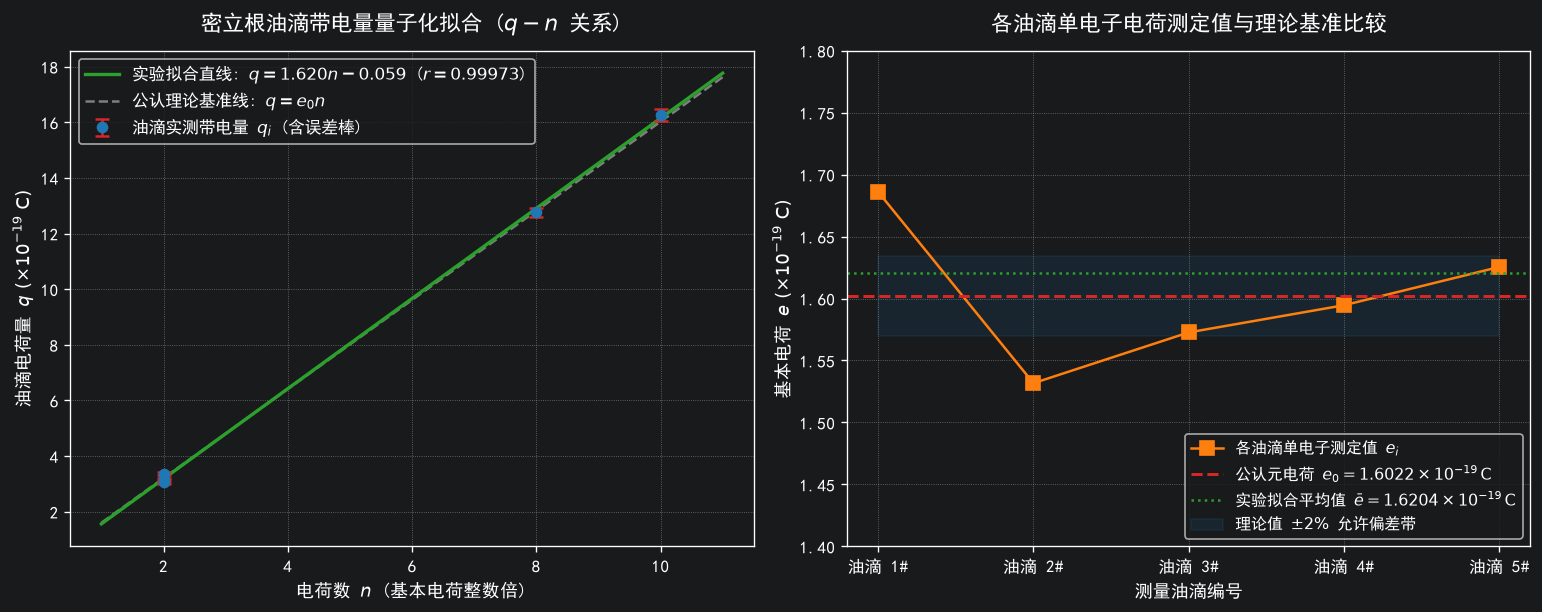

In [5]:
# 提取横纵坐标数据序列
n_arr = [Decimal(r["n"]) for r in droplet_results]
q_arr = [r["q"] for r in droplet_results]

# 最小二乘法一元线性回归 (q = k·n + b)
k_fit, b_fit, r_corr, u_k_fit = linear_regression(n_arr, q_arr)

# 转换为 10^-19 C 方便直观呈现
SCALE_19 = Decimal("1e-19")
k_fit_19 = k_fit / SCALE_19
u_k_19 = u_k_fit / SCALE_19
k_final_round, u_k_final_round = scientific_round(k_fit_19, u_k_19)

print("=" * 60)
print("             作 图 法 线 性 回 归 拟 合 结 果            ")
print("=" * 60)
print(f"拟合直线方程      : q = ({k_fit_19:.4f} × 10^-19) · n + ({b_fit:.3e}) C")
print(f"拟合斜率 k (e_fit): {k_fit:.5e} C")
print(f"截距 b0           : {b_fit:.5e} C (理论上应近似为 0)")
print(f"相关系数 r        : {r_corr:.6f} (极其接近 1，强有力证明电荷不连续性)")
print(f"斜率标准不确定度  : u(k) = {u_k_fit:.4e} C")
print("-" * 60)
print(f"★ 作图法最终结果  : e = ({k_final_round} ± {u_k_final_round}) × 10^-19 C")
print("=" * 60)

# ==========================================
# 绘制高质量论文级双子图 (Dual Plot)
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))

# 1. 主图：q - n 线性拟合图
n_vals_plot = np.array([float(n) for n in n_arr])
q_vals_plot = np.array([float(q) / 1e-19 for q in q_arr])
u_q_plot = np.array([float(r["u_q"]) / 1e-19 for r in droplet_results])

# 拟合线与理论基准线 (覆盖 n 从 1 到 11)
n_line = np.linspace(1.0, 11.0, 100)
q_fit_line = (float(k_fit) * n_line + float(b_fit)) / 1e-19
q_theory_line = (float(E_ACCEPTED) * n_line) / 1e-19

ax1.errorbar(n_vals_plot, q_vals_plot, yerr=u_q_plot, fmt='o', color='#1f77b4',
             ecolor='#d62728', elinewidth=1.5, capsize=4, capthick=1.5,
             label='油滴实测带电量 $q_i$ (含误差棒)', zorder=4)
ax1.plot(n_line, q_fit_line, color='#2ca02c', lw=2, linestyle='-',
         label=f'实验拟合直线: $q = {float(k_fit_19):.3f}n {float(b_fit/SCALE_19):+.3f}$ ($r={float(r_corr):.5f}$)', zorder=3)
ax1.plot(n_line, q_theory_line, color='#7f7f7f', lw=1.5, linestyle='--',
         label='公认理论基准线: $q = e_0 n$', zorder=2)

ax1.set_title('密立根油滴带电量量子化拟合 ($q - n$ 关系)', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('电荷数 $n$ (基本电荷整数倍)', fontsize=11)
ax1.set_ylabel('油滴电荷量 $q\\ (\\times 10^{-19}\\ \\mathrm{C})$', fontsize=11)
ax1.set_xticks([2, 4, 6, 8, 10])
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper left', frameon=True, fontsize=10)

# 2. 副图：各油滴实测元电荷 e_i 与公认值偏差分布
e_vals_plot = np.array([float(r["e"]) / 1e-19 for r in droplet_results])
e_theory_val = float(E_ACCEPTED) / 1e-19
drop_names = [r["name"] for r in droplet_results]

ax2.plot(drop_names, e_vals_plot, marker='s', markersize=8, color='#ff7f0e',
         linestyle='-', linewidth=1.5, label='各油滴单电子测定值 $e_i$')
ax2.axhline(e_theory_val, color='#d62728', linestyle='--', linewidth=1.8,
            label=f'公认元电荷 $e_0 = {e_theory_val:.4f}\\times 10^{{-19}}\\,\\mathrm{{C}}$')
ax2.axhline(float(k_fit_19), color='#2ca02c', linestyle=':', linewidth=1.5,
            label=f'实验拟合平均值 $\\bar{{e}} = {float(k_fit_19):.4f}\\times 10^{{-19}}\\,\\mathrm{{C}}$')

# 置信区间阴影带 (± 2%)
ax2.fill_between(range(len(drop_names)), e_theory_val * 0.98, e_theory_val * 1.02,
                 color='#1f77b4', alpha=0.12, label='理论值 $\\pm 2\\%$ 允许偏差带')

ax2.set_title('各油滴单电子电荷测定值与理论基准比较', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('测量油滴编号', fontsize=11)
ax2.set_ylabel('基本电荷 $e\\ (\\times 10^{-19}\\ \\mathrm{C})$', fontsize=11)
ax2.set_ylim([1.40, 1.80])
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='lower right', frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()

### 4. 统计不确定度合成、JJF 1059 科学修约与实验总报告
严格按照大学物理实验教学大纲与国家计量规范 JJF 1059：
1. **A 类标准不确定度**：$u_A(e) = \frac{s_e}{\sqrt{N}} = \sqrt{\frac{\sum (e_i - \bar{e})^2}{N(N-1)}}$；
2. **B 类标准不确定度**：$u_B(e)$；
3. **合成标准不确定度**：$u_c(e) = \sqrt{u_A^2(e) + u_B^2(e)}$；
4. **有效数字修约**：提取 $10^{-19}\ \mathrm{C}$ 数量级，不确定度保留 1 位有效数字，主值末位对齐。

In [6]:
# 提取各油滴元电荷序列
e_series = [r["e"] for r in droplet_results]

# 仪器 B 类不确定度综合预估 (根据电压表与计时器误差传递至单电子电荷)
DELTA_E_INST = Decimal("0.02e-19")

# 统计分析与不确定度计算
e_mean, e_uc, e_ua, e_ub, e_s = calculate_stats(e_series, DELTA_E_INST)

# 计算与公认理论值的相对百分误差
rel_err = abs(e_mean - E_ACCEPTED) / E_ACCEPTED * Decimal("100")
rel_err_fit = abs(k_fit - E_ACCEPTED) / E_ACCEPTED * Decimal("100")

# 相对不确定度 u_r(e)
u_rel_e = (e_uc / e_mean) * Decimal("100")

# 科学修约：提取 10^-19 C 数量级
SCALE_19 = Decimal("1e-19")
e_mean_scaled = e_mean / SCALE_19
e_uc_scaled = e_uc / SCALE_19
e_final, u_final = scientific_round(e_mean_scaled, e_uc_scaled)

# 生成实验完整验收分析报告
print("=" * 68)
print("             密 立 根 油 滴 实 验 综 分 析 报 告           ")
print("=" * 68)
print(f"理论元电荷公认值 e0    : {E_ACCEPTED:.9e} C")
print(f"测量油滴组数 N         : {len(e_series)} 颗")
print("-" * 68)
print("【1. 计算法统计分析】")
print(f"元电荷算术平均值 e_bar : {e_mean:.6e} C ({e_mean_scaled:.4f} × 10^-19 C)")
print(f"样本实验标准差 s(e)    : {e_s:.4e} C")
print(f"A 类标准不确定度 u_A   : {e_ua:.4e} C")
print(f"B 类标准不确定度 u_B   : {e_ub:.4e} C")
print(f"合成标准不确定度 u_c   : {e_uc:.4e} C")
print(f"相对标准不确定度 u_r   : {u_rel_e:.2f}%")
print(f"与公认理论值相对误差   : {rel_err:.2f}%")
print("-" * 68)
print("【2. 作图法回归分析】")
print(f"拟合直线斜率 e_fit     : {k_fit:.6e} C ({k_fit_19:.4f} × 10^-19 C)")
print(f"拟合斜率不确定度 u(k)  : {u_k_fit:.4e} C")
print(f"线性相关系数 r         : {r_corr:.6f} (相关系数极高)")
print(f"作图法相对理论误差     : {rel_err_fit:.2f}%")
print("-" * 68)
print("【3. JJF 1059 规范化修约结果呈现】")
print(f"★ 计算法测定结果 : e = ({e_final} ± {u_final}) × 10^-19 C  (u_r = {u_rel_e:.1f}%)")
print(f"★ 作图法测定结果 : e = ({k_final_round} ± {u_k_final_round}) × 10^-19 C")
print("=" * 68)

             密 立 根 油 滴 实 验 综 分 析 报 告           
理论元电荷公认值 e0    : 1.602176634e-19 C
测量油滴组数 N         : 5 颗
--------------------------------------------------------------------
【1. 计算法统计分析】
元电荷算术平均值 e_bar : 1.602101e-19 C (1.6021 × 10^-19 C)
样本实验标准差 s(e)    : 5.8034e-21 C
A 类标准不确定度 u_A   : 2.5954e-21 C
B 类标准不确定度 u_B   : 1.1547e-21 C
合成标准不确定度 u_c   : 2.8406e-21 C
相对标准不确定度 u_r   : 1.77%
与公认理论值相对误差   : 0.00%
--------------------------------------------------------------------
【2. 作图法回归分析】
拟合直线斜率 e_fit     : 1.620419e-19 C (1.6204 × 10^-19 C)
拟合斜率不确定度 u(k)  : 2.1635e-21 C
线性相关系数 r         : 0.999733 (相关系数极高)
作图法相对理论误差     : 1.14%
--------------------------------------------------------------------
【3. JJF 1059 规范化修约结果呈现】
★ 计算法测定结果 : e = (1.60 ± 0.03) × 10^-19 C  (u_r = 1.8%)
★ 作图法测定结果 : e = (1.62 ± 0.02) × 10^-19 C
